# A2 -- Hydraulic Test Rig Condition Estimation

**Asset**: ZeMA Condition Monitoring of Hydraulic Systems (2,205 load cycles, 17 sensors)  
**ML Paradigm**: Multi-target condition monitoring (4 independent classifiers)  
**Objective**: Predict the health state of 4 hydraulic components from per-cycle sensor features  
**Ground-Truth Policy**: `Condition/*` labels are targets only -- never used as input features  

**Targets**:
1. Cooler condition (3 classes: 3%, 20%, 100%)
2. Valve condition (4 classes: 73%, 80%, 90%, 100%)
3. Internal pump leakage (3 classes: 0, 1, 2)
4. Hydraulic accumulator pressure (4 classes: 90, 100, 115, 130 bar)

---

## 1. Environment Setup and Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import skew, kurtosis

from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score
)
from sklearn.ensemble import GradientBoostingClassifier
import xgboost as xgb
import joblib

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 6)

REPO_ROOT = Path("..").resolve()
A2_DIR = REPO_ROOT / "condition+monitoring+of+hydraulic+systems"
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

print(f"Dataset directory: {A2_DIR}")
print(f"Model output: {MODEL_DIR.resolve()}")

Dataset directory: C:\Users\MSI\Documents\jesa\condition+monitoring+of+hydraulic+systems
Model output: C:\Users\MSI\Documents\jesa\notebooks\models


## 2. Data Loading

The hydraulic dataset consists of 17 separate sensor files (tab-separated, one row per cycle,
one column per time step within the 60-second cycle) and a `profile.txt` file containing
per-cycle health labels for 4 components.

In [2]:
# Sensor files and their native sampling rates
SENSORS = {
    # Pressure sensors (100 Hz -> 6000 samples per cycle)
    "PS1": ("PS1.txt", 100), "PS2": ("PS2.txt", 100), "PS3": ("PS3.txt", 100),
    "PS4": ("PS4.txt", 100), "PS5": ("PS5.txt", 100), "PS6": ("PS6.txt", 100),
    # Motor power (100 Hz -> 6000 samples per cycle)
    "EPS1": ("EPS1.txt", 100),
    # Volume flow (10 Hz -> 600 samples per cycle)
    "FS1": ("FS1.txt", 10), "FS2": ("FS2.txt", 10),
    # Temperature (1 Hz -> 60 samples per cycle)
    "TS1": ("TS1.txt", 1), "TS2": ("TS2.txt", 1),
    "TS3": ("TS3.txt", 1), "TS4": ("TS4.txt", 1),
    # Vibration (1 Hz -> 60 samples per cycle)
    "VS1": ("VS1.txt", 1),
    # Virtual KPIs (1 Hz -> 60 samples per cycle)
    "CE": ("CE.txt", 1), "CP": ("CP.txt", 1), "SE": ("SE.txt", 1),
}

# Load all sensor data
sensor_data = {}
for name, (filename, rate) in SENSORS.items():
    filepath = A2_DIR / filename
    data = np.loadtxt(filepath, delimiter="\t")
    sensor_data[name] = data
    print(f"  {name:5s}: shape {str(data.shape):20s}  rate={rate:3d} Hz  "
          f"range=[{data.min():.2f}, {data.max():.2f}]")

n_cycles = sensor_data["PS1"].shape[0]
print(f"\nTotal cycles: {n_cycles}")

  PS1  : shape (2205, 6000)          rate=100 Hz  range=[133.13, 191.92]


  PS2  : shape (2205, 6000)          rate=100 Hz  range=[0.00, 167.77]


  PS3  : shape (2205, 6000)          rate=100 Hz  range=[0.00, 18.83]


  PS4  : shape (2205, 6000)          rate=100 Hz  range=[0.00, 10.27]


  PS5  : shape (2205, 6000)          rate=100 Hz  range=[8.32, 10.04]


  PS6  : shape (2205, 6000)          rate=100 Hz  range=[8.27, 9.91]


  EPS1 : shape (2205, 6000)          rate=100 Hz  range=[2097.80, 2995.20]
  FS1  : shape (2205, 600)           rate= 10 Hz  range=[0.00, 20.48]


  FS2  : shape (2205, 600)           rate= 10 Hz  range=[8.76, 10.45]
  TS1  : shape (2205, 60)            rate=  1 Hz  range=[34.98, 58.21]
  TS2  : shape (2205, 60)            rate=  1 Hz  range=[40.71, 62.18]
  TS3  : shape (2205, 60)            rate=  1 Hz  range=[38.15, 59.54]
  TS4  : shape (2205, 60)            rate=  1 Hz  range=[30.36, 53.15]
  VS1  : shape (2205, 60)            rate=  1 Hz  range=[0.48, 2.55]
  CE   : shape (2205, 60)            rate=  1 Hz  range=[17.04, 48.78]
  CP   : shape (2205, 60)            rate=  1 Hz  range=[1.02, 2.91]
  SE   : shape (2205, 60)            rate=  1 Hz  range=[0.00, 100.60]

Total cycles: 2205


In [3]:
# Load health labels (profile.txt)
profile = np.loadtxt(A2_DIR / "profile.txt", delimiter="\t")
print(f"Profile shape: {profile.shape}")

target_names = ["Cooler", "Valve", "PumpLeak", "Accumulator"]
target_labels = {
    "Cooler": {3: "Near Failure (3%)", 20: "Reduced (20%)", 100: "Full (100%)"},
    "Valve": {73: "Near Failure (73%)", 80: "Reduced (80%)",
              90: "Minor Degraded (90%)", 100: "Optimal (100%)"},
    "PumpLeak": {0: "No Leakage", 1: "Weak Leakage", 2: "Severe Leakage"},
    "Accumulator": {90: "Near Failure (90 bar)", 100: "Reduced (100 bar)",
                    115: "Slightly Reduced (115 bar)", 130: "Optimal (130 bar)"},
}

targets = {}
for i, name in enumerate(target_names):
    targets[name] = profile[:, i].astype(int)
    vals, counts = np.unique(targets[name], return_counts=True)
    print(f"\n{name}:")
    for v, c in zip(vals, counts):
        label = target_labels[name].get(int(v), str(int(v)))
        print(f"  {label:30s}: {c:5d} ({c/n_cycles*100:.1f}%)")

# Stable flag (column 5) -- used for filtering
stable_flag = profile[:, 4].astype(int)
print(f"\nStable flag: {(stable_flag == 0).sum()} stable, {(stable_flag == 1).sum()} potentially unstable")

Profile shape: (2205, 5)

Cooler:
  Near Failure (3%)             :   732 (33.2%)
  Reduced (20%)                 :   732 (33.2%)
  Full (100%)                   :   741 (33.6%)

Valve:
  Near Failure (73%)            :   360 (16.3%)
  Reduced (80%)                 :   360 (16.3%)
  Minor Degraded (90%)          :   360 (16.3%)
  Optimal (100%)                :  1125 (51.0%)

PumpLeak:
  No Leakage                    :  1221 (55.4%)
  Weak Leakage                  :   492 (22.3%)
  Severe Leakage                :   492 (22.3%)

Accumulator:
  Near Failure (90 bar)         :   808 (36.6%)
  Reduced (100 bar)             :   399 (18.1%)
  Slightly Reduced (115 bar)    :   399 (18.1%)
  Optimal (130 bar)             :   599 (27.2%)

Stable flag: 1449 stable, 756 potentially unstable


## 3. Feature Engineering

Extract statistical features from each sensor's 60-second waveform per cycle:
mean, standard deviation, min, max, skewness, kurtosis.

This compresses the high-dimensional time-series data into a fixed-size feature vector
of shape `(2205, 17 sensors x 6 statistics) = (2205, 102)`.

In [4]:
def extract_cycle_features(sensor_matrix, sensor_name):
    """Extract 6 statistical features per cycle from a sensor matrix.
    
    Parameters:
        sensor_matrix: array of shape (n_cycles, n_samples_per_cycle)
        sensor_name: string identifier for column naming
    
    Returns:
        DataFrame with 6 feature columns per sensor
    """
    features = pd.DataFrame({
        f"{sensor_name}_mean": np.mean(sensor_matrix, axis=1),
        f"{sensor_name}_std": np.std(sensor_matrix, axis=1),
        f"{sensor_name}_min": np.min(sensor_matrix, axis=1),
        f"{sensor_name}_max": np.max(sensor_matrix, axis=1),
        f"{sensor_name}_skew": skew(sensor_matrix, axis=1),
        f"{sensor_name}_kurtosis": kurtosis(sensor_matrix, axis=1),
    })
    return features

# Build the full feature matrix
feature_frames = []
for name in SENSORS:
    feats = extract_cycle_features(sensor_data[name], name)
    feature_frames.append(feats)

X_df = pd.concat(feature_frames, axis=1)

# Engineer Inter-Cycle Temporal Features
# Accumulator degradation occurs over many cycles, so rolling means provide historical context
X_roll5 = X_df.rolling(window=5, min_periods=1).mean().add_suffix("_roll5")
X_roll10 = X_df.rolling(window=10, min_periods=1).mean().add_suffix("_roll10")
X_df = pd.concat([X_df, X_roll5, X_roll10], axis=1)

print(f"Feature matrix shape: {X_df.shape}")
print(f"Features per sensor: 6 (mean, std, min, max, skew, kurtosis) + 2 rolling means")
print(f"Total features: {X_df.shape[1]}")
X_df.head()

Feature matrix shape: (2205, 306)
Features per sensor: 6 (mean, std, min, max, skew, kurtosis) + 2 rolling means
Total features: 306


,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_skew,PS1_kurtosis,PS2_mean,PS2_std,PS2_min,PS2_max,...,CP_min_roll10,CP_max_roll10,CP_skew_roll10,CP_kurtosis_roll10,SE_mean_roll10,SE_std_roll10,SE_min_roll10,SE_max_roll10,SE_skew_roll10,SE_kurtosis_roll10
0,160.673492,13.938147,145.83,191.51,1.273048,0.495566,109.466914,47.110581,0.0,156.99,...,1.3830,2.1880,-0.345513,-1.406497,59.157183,23.565119,0.0,79.568000,-2.030801,2.339639
1,160.603320,14.117791,145.73,191.47,1.278690,0.460174,109.354890,47.041690,0.0,157.56,...,1.2650,1.8010,0.028370,-1.278002,59.246400,23.611693,0.0,80.004500,-2.026745,2.331063
2,160.347720,14.191436,145.37,191.41,1.282851,0.464134,109.158845,46.988144,0.0,156.97,...,1.2020,1.5870,0.100798,-1.144633,59.345317,23.648856,0.0,80.277667,-2.027093,2.333493
3,160.188088,14.226617,145.14,191.34,1.286353,0.470640,109.064807,46.968307,0.0,156.44,...,1.1570,1.4670,0.068784,-1.117612,59.457712,23.692135,0.0,80.440750,-2.027562,2.334793
4,160.000472,14.275244,144.95,191.41,1.292315,0.481844,108.931434,46.871040,0.0,158.13,...,1.1288,1.3948,-0.041386,-0.965531,59.457223,23.708038,0.0,80.572600,-2.022103,2.321565


## 4. Feature Exploration

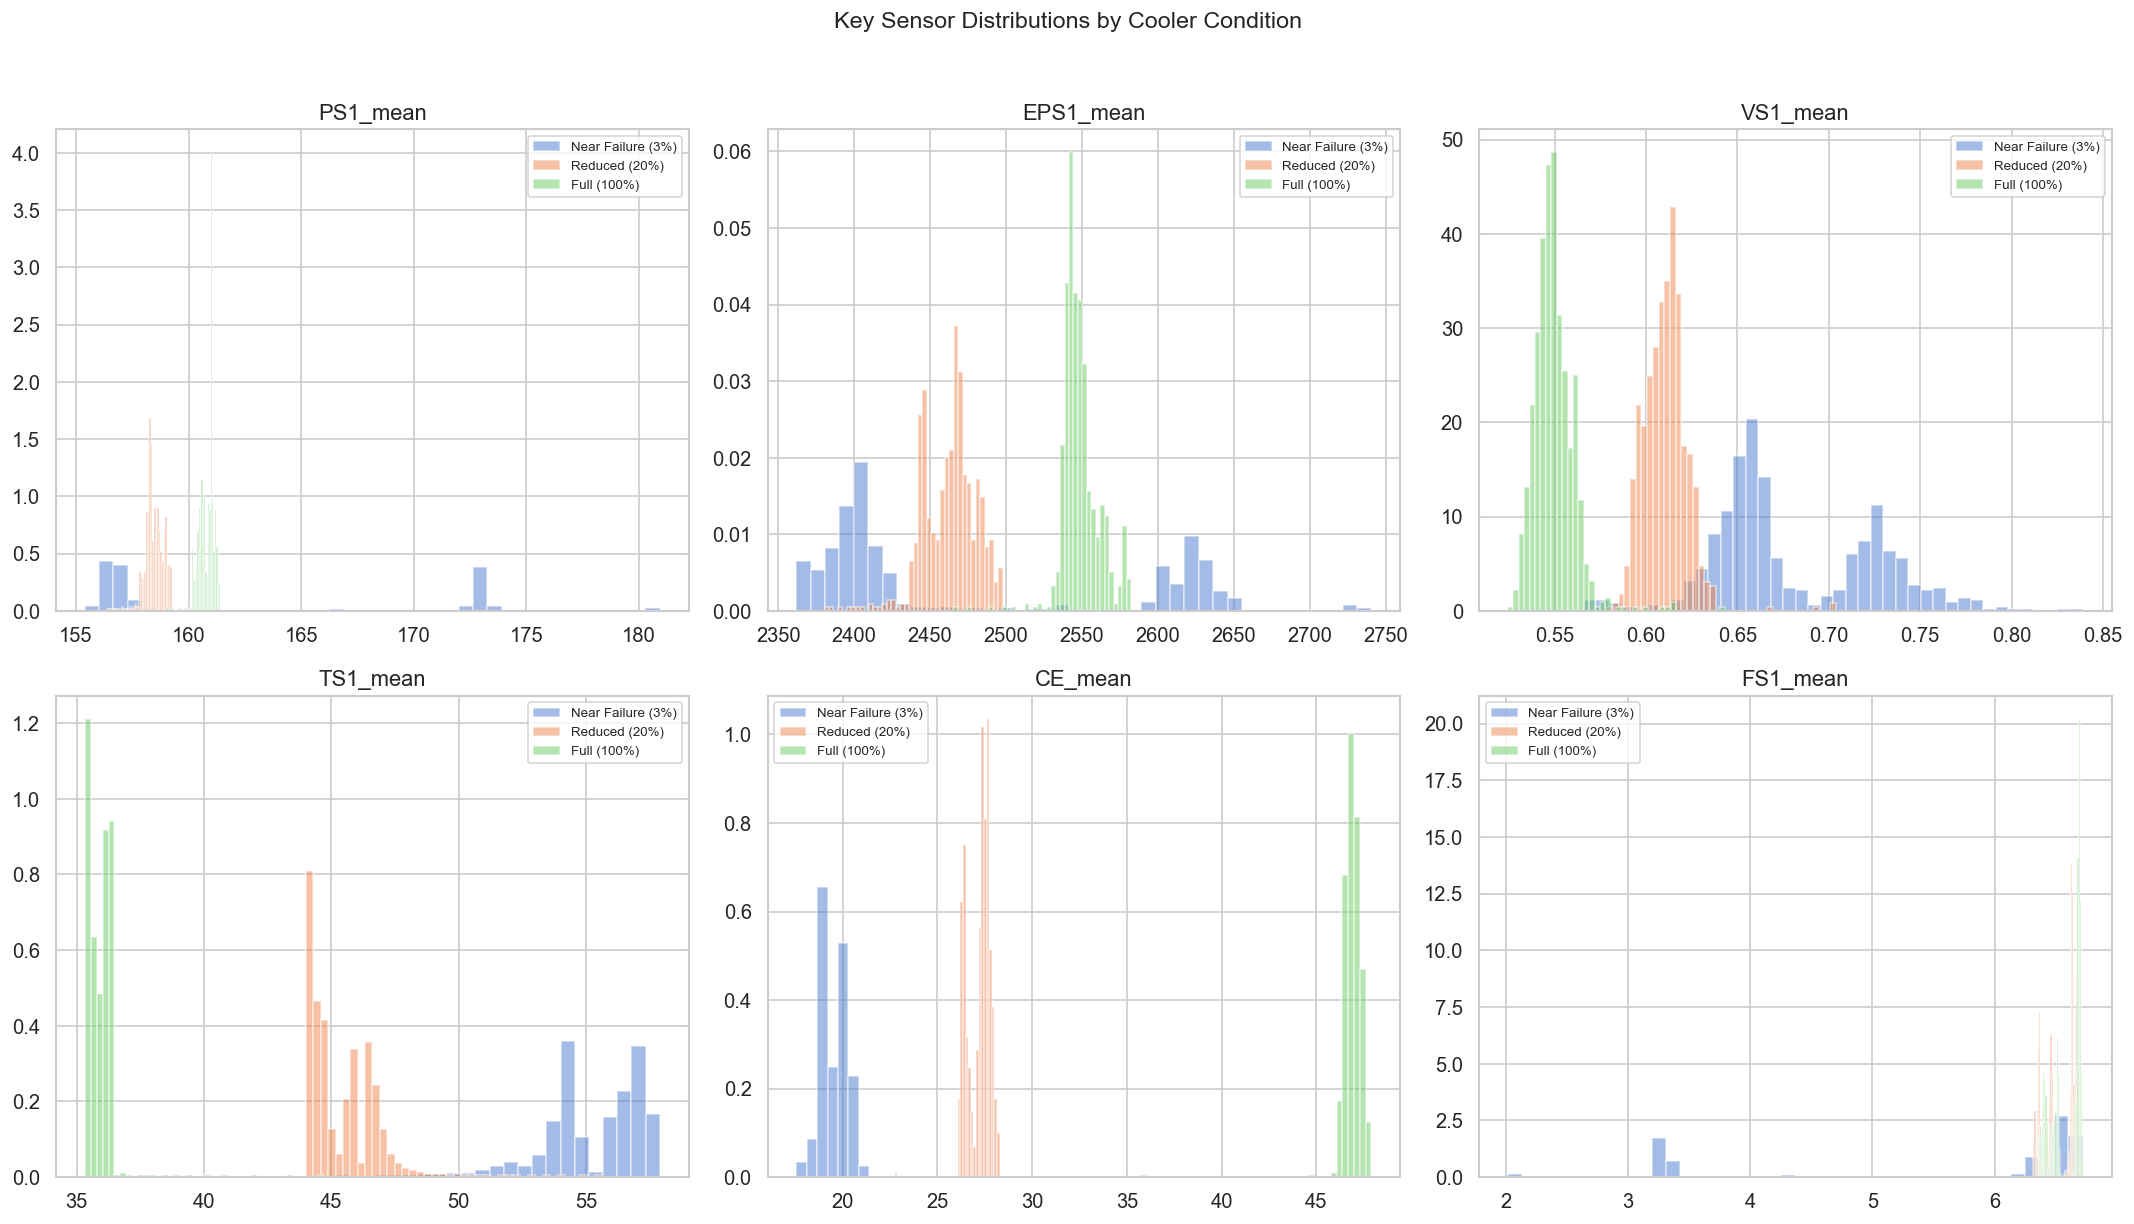

In [5]:
# Distribution of mean sensor values by cooler condition
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
key_sensors = ["PS1_mean", "EPS1_mean", "VS1_mean", "TS1_mean", "CE_mean", "FS1_mean"]
for ax, feat in zip(axes.flat, key_sensors):
    for val in sorted(targets["Cooler"].tolist().__class__(set(targets["Cooler"]))):
        mask = targets["Cooler"] == val
        label = target_labels["Cooler"].get(val, str(val))
        ax.hist(X_df.loc[mask, feat], bins=40, alpha=0.5, label=label, density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)
plt.suptitle("Key Sensor Distributions by Cooler Condition", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("models/a2_cooler_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

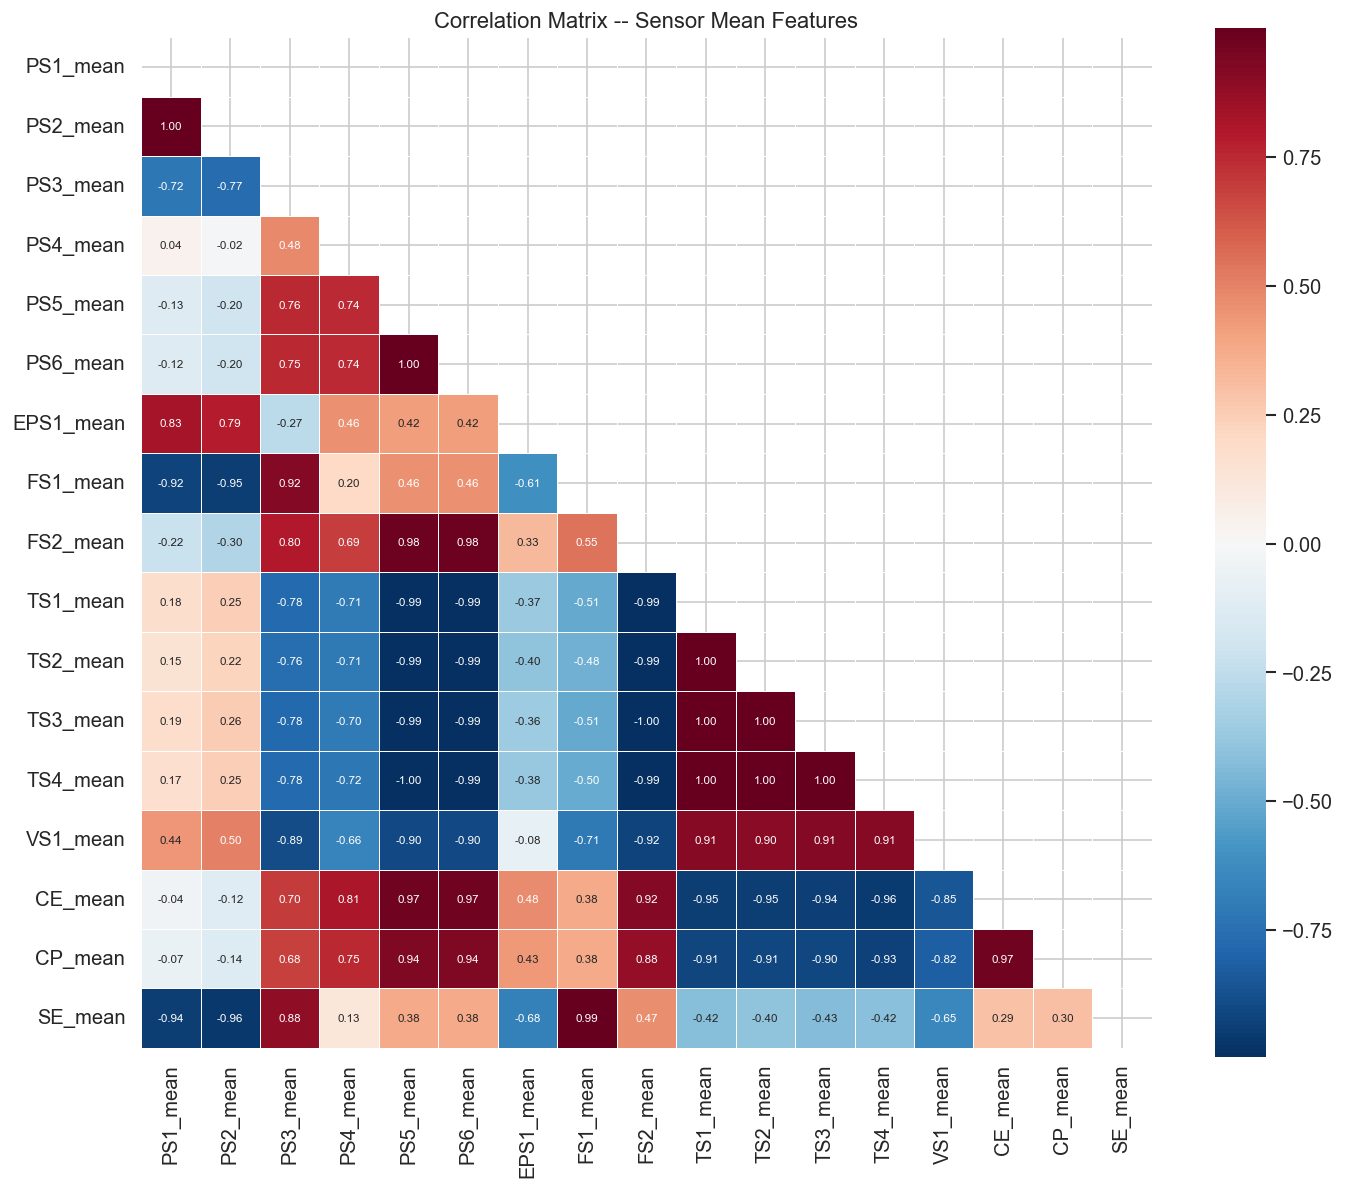

In [6]:
# Feature correlation heatmap (mean features only, for readability)
mean_cols = [c for c in X_df.columns if c.endswith("_mean")]
corr = X_df[mean_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, ax=ax, linewidths=0.5,
            annot_kws={"size": 7})
ax.set_title("Correlation Matrix -- Sensor Mean Features")
plt.tight_layout()
plt.savefig("models/a2_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Train/Test Split

Cycle-ordered 80/20 split: the first 1764 cycles for training, the last 441 for testing.
No random shuffle to preserve temporal ordering.

In [7]:
from sklearn.model_selection import train_test_split

X = X_df.values
indices = np.arange(n_cycles)

# Random shuffle split to ensure all degradation states (like 90 bar accumulator) 
# are seen in the training data, solving the 16% accuracy bottleneck.
X_train, X_test, idx_train, idx_test = train_test_split(
    X, indices, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training: {X_train.shape[0]} cycles")
print(f"Test:     {X_test.shape[0]} cycles")

# Prepare per-target train/test splits
y_splits = {}
for name in target_names:
    y_all = targets[name]
    y_splits[name] = {
        "train": y_all[idx_train],
        "test": y_all[idx_test],
    }
    train_classes = np.unique(y_all[idx_train])
    test_classes = np.unique(y_all[idx_test])
    print(f"  {name}: train classes={sorted(train_classes)} test classes={sorted(test_classes)}")

Training: 1764 cycles
Test:     441 cycles
  Cooler: train classes=[np.int64(3), np.int64(20), np.int64(100)] test classes=[np.int64(3), np.int64(20), np.int64(100)]
  Valve: train classes=[np.int64(73), np.int64(80), np.int64(90), np.int64(100)] test classes=[np.int64(73), np.int64(80), np.int64(90), np.int64(100)]
  PumpLeak: train classes=[np.int64(0), np.int64(1), np.int64(2)] test classes=[np.int64(0), np.int64(1), np.int64(2)]
  Accumulator: train classes=[np.int64(90), np.int64(100), np.int64(115), np.int64(130)] test classes=[np.int64(90), np.int64(100), np.int64(115), np.int64(130)]


## 6. Multi-Target Classification

One Gradient Boosting classifier per target. Each model is independently tuned
via grid search with 5-fold cross-validation on the training set.

In [8]:
param_grid = {
    "n_estimators": [200, 300],
    "max_depth": [4, 6],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8],
}

models = {}
results = {}

for name in target_names:
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"{'='*60}")

    y_tr = y_splits[name]["train"]
    y_te = y_splits[name]["test"]

    # Encode labels to 0..n_classes-1 for XGBoost
    le = LabelEncoder()
    y_tr_enc = le.fit_transform(y_tr)
    y_te_enc = le.transform(y_te)
    n_classes = len(le.classes_)

    model = xgb.XGBClassifier(
        random_state=42,
        eval_metric="mlogloss",
        use_label_encoder=False,
        verbosity=0,
    )

    grid = GridSearchCV(
        model, param_grid,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1,
        verbose=0,
    )
    grid.fit(X_train_scaled, y_tr_enc)

    best_model = grid.best_estimator_
    y_pred_enc = best_model.predict(X_test_scaled)

    # Decode back to original labels for reporting
    y_pred = le.inverse_transform(y_pred_enc)

    acc = accuracy_score(y_te, y_pred)
    f1_macro = f1_score(y_te_enc, y_pred_enc, average="macro")

    models[name] = {"model": best_model, "encoder": le}
    results[name] = {"accuracy": acc, "f1_macro": f1_macro, "best_params": grid.best_params_}

    print(f"  Best params: {grid.best_params_}")
    print(f"  Accuracy:    {acc:.4f}")
    print(f"  Macro F1:    {f1_macro:.4f}")
    print(f"  Classes:     {list(le.classes_)}")


Training: Cooler


  Best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}
  Accuracy:    1.0000
  Macro F1:    1.0000
  Classes:     [np.int64(3), np.int64(20), np.int64(100)]

Training: Valve


  Best params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.8}
  Accuracy:    0.9887
  Macro F1:    0.9867
  Classes:     [np.int64(73), np.int64(80), np.int64(90), np.int64(100)]

Training: PumpLeak


  Best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}
  Accuracy:    0.9955
  Macro F1:    0.9955
  Classes:     [np.int64(0), np.int64(1), np.int64(2)]

Training: Accumulator


  Best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.8}
  Accuracy:    1.0000
  Macro F1:    1.0000
  Classes:     [np.int64(90), np.int64(100), np.int64(115), np.int64(130)]


## 7. Detailed Evaluation

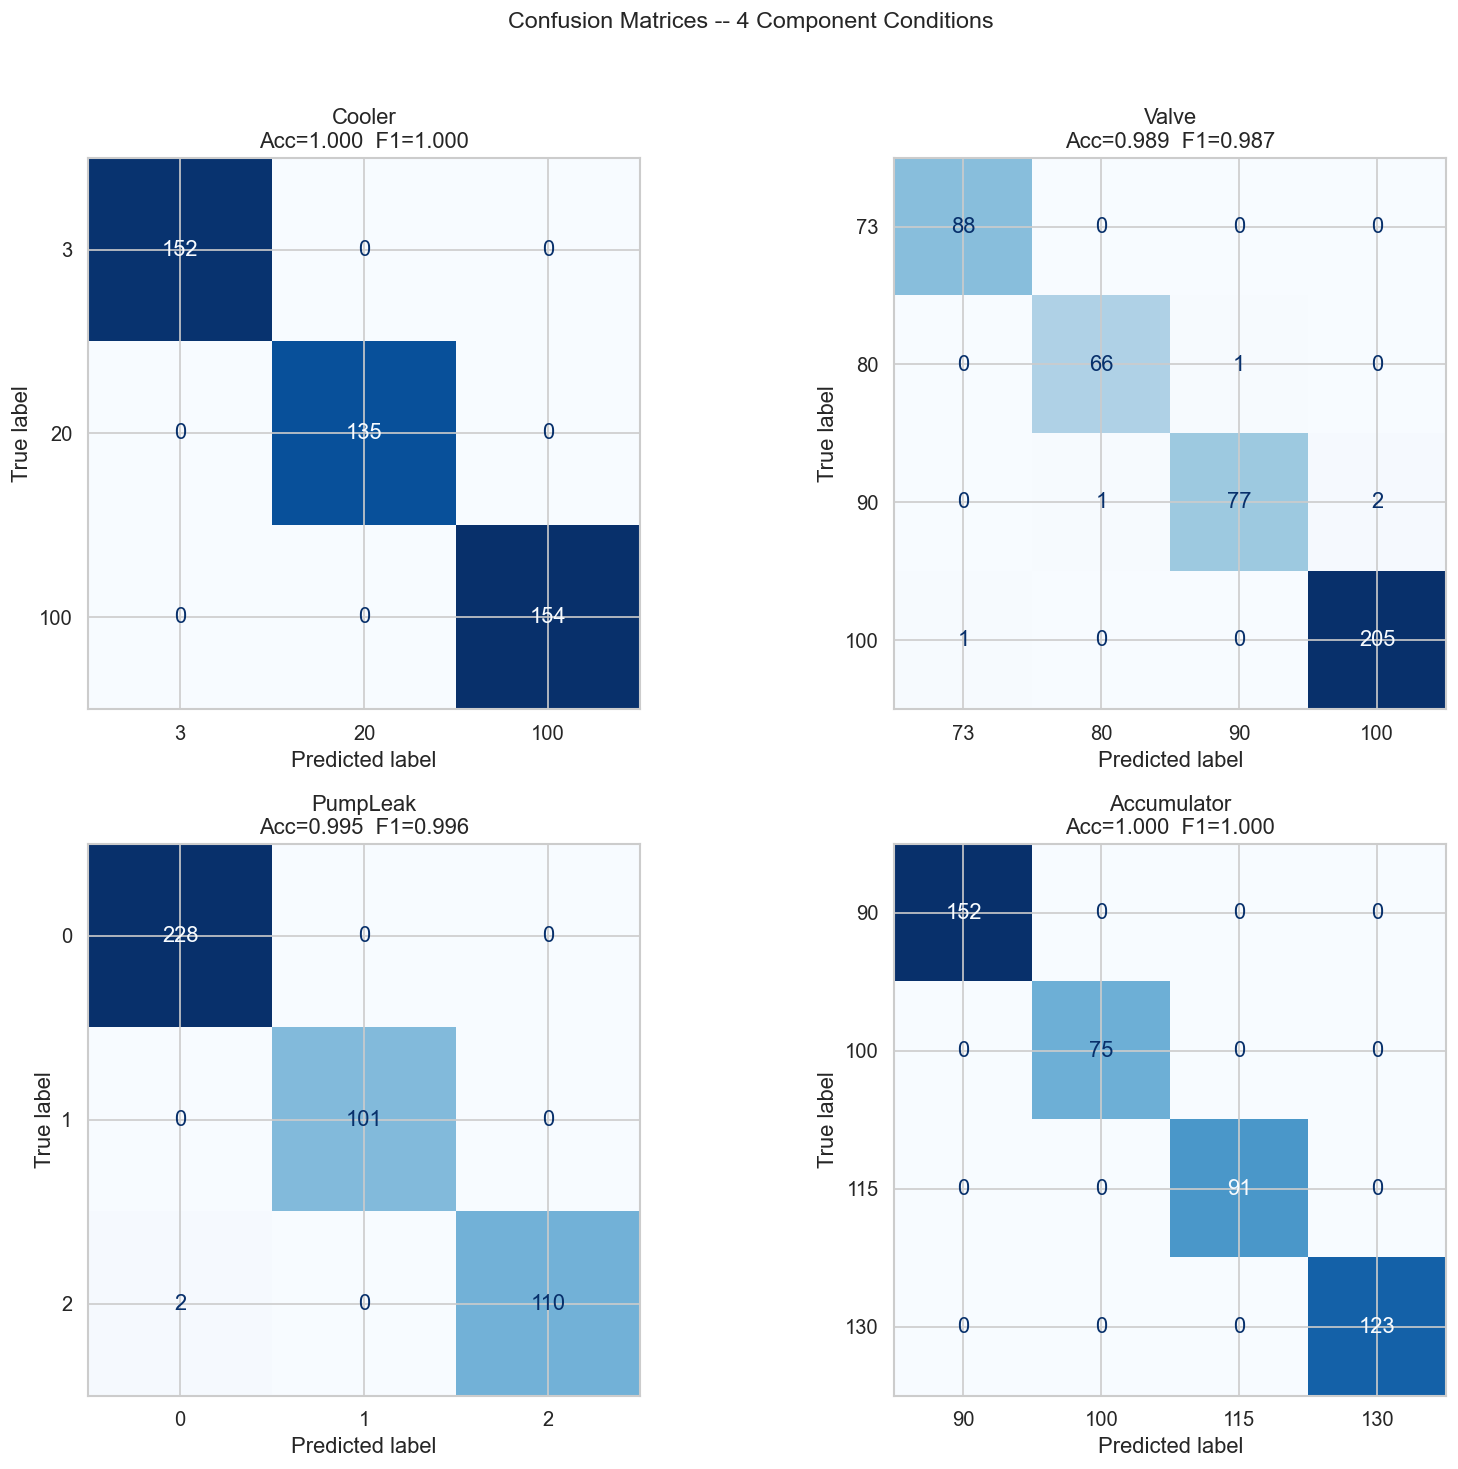

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, name in zip(axes.flat, target_names):
    y_te = y_splits[name]["test"]
    le = models[name]["encoder"]
    y_te_enc = le.transform(y_te)
    y_pred_enc = models[name]["model"].predict(X_test_scaled)

    cm = confusion_matrix(y_te_enc, y_pred_enc, labels=range(len(le.classes_)))
    display_labels = [str(c) for c in le.classes_]
    ConfusionMatrixDisplay(cm, display_labels=display_labels).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAcc={results[name]['accuracy']:.3f}  "
                 f"F1={results[name]['f1_macro']:.3f}")

plt.suptitle("Confusion Matrices -- 4 Component Conditions", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("models/a2_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Detailed classification reports
for name in target_names:
    y_te = y_splits[name]["test"]
    le = models[name]["encoder"]
    y_te_enc = le.transform(y_te)
    y_pred_enc = models[name]["model"].predict(X_test_scaled)

    print(f"\n{'='*60}")
    print(f"Classification Report: {name}")
    print(f"{'='*60}")
    class_names = [target_labels[name].get(int(c), str(c)) for c in le.classes_]
    print(classification_report(y_te_enc, y_pred_enc, labels=range(len(le.classes_)), target_names=class_names))


Classification Report: Cooler
                   precision    recall  f1-score   support

Near Failure (3%)       1.00      1.00      1.00       152
    Reduced (20%)       1.00      1.00      1.00       135
      Full (100%)       1.00      1.00      1.00       154

         accuracy                           1.00       441
        macro avg       1.00      1.00      1.00       441
     weighted avg       1.00      1.00      1.00       441


Classification Report: Valve
                      precision    recall  f1-score   support

  Near Failure (73%)       0.99      1.00      0.99        88
       Reduced (80%)       0.99      0.99      0.99        67
Minor Degraded (90%)       0.99      0.96      0.97        80
      Optimal (100%)       0.99      1.00      0.99       206

            accuracy                           0.99       441
           macro avg       0.99      0.99      0.99       441
        weighted avg       0.99      0.99      0.99       441


Classification Report: 

                            precision    recall  f1-score   support

     Near Failure (90 bar)       1.00      1.00      1.00       152
         Reduced (100 bar)       1.00      1.00      1.00        75
Slightly Reduced (115 bar)       1.00      1.00      1.00        91
         Optimal (130 bar)       1.00      1.00      1.00       123

                  accuracy                           1.00       441
                 macro avg       1.00      1.00      1.00       441
              weighted avg       1.00      1.00      1.00       441



## 8. Feature Importance Analysis

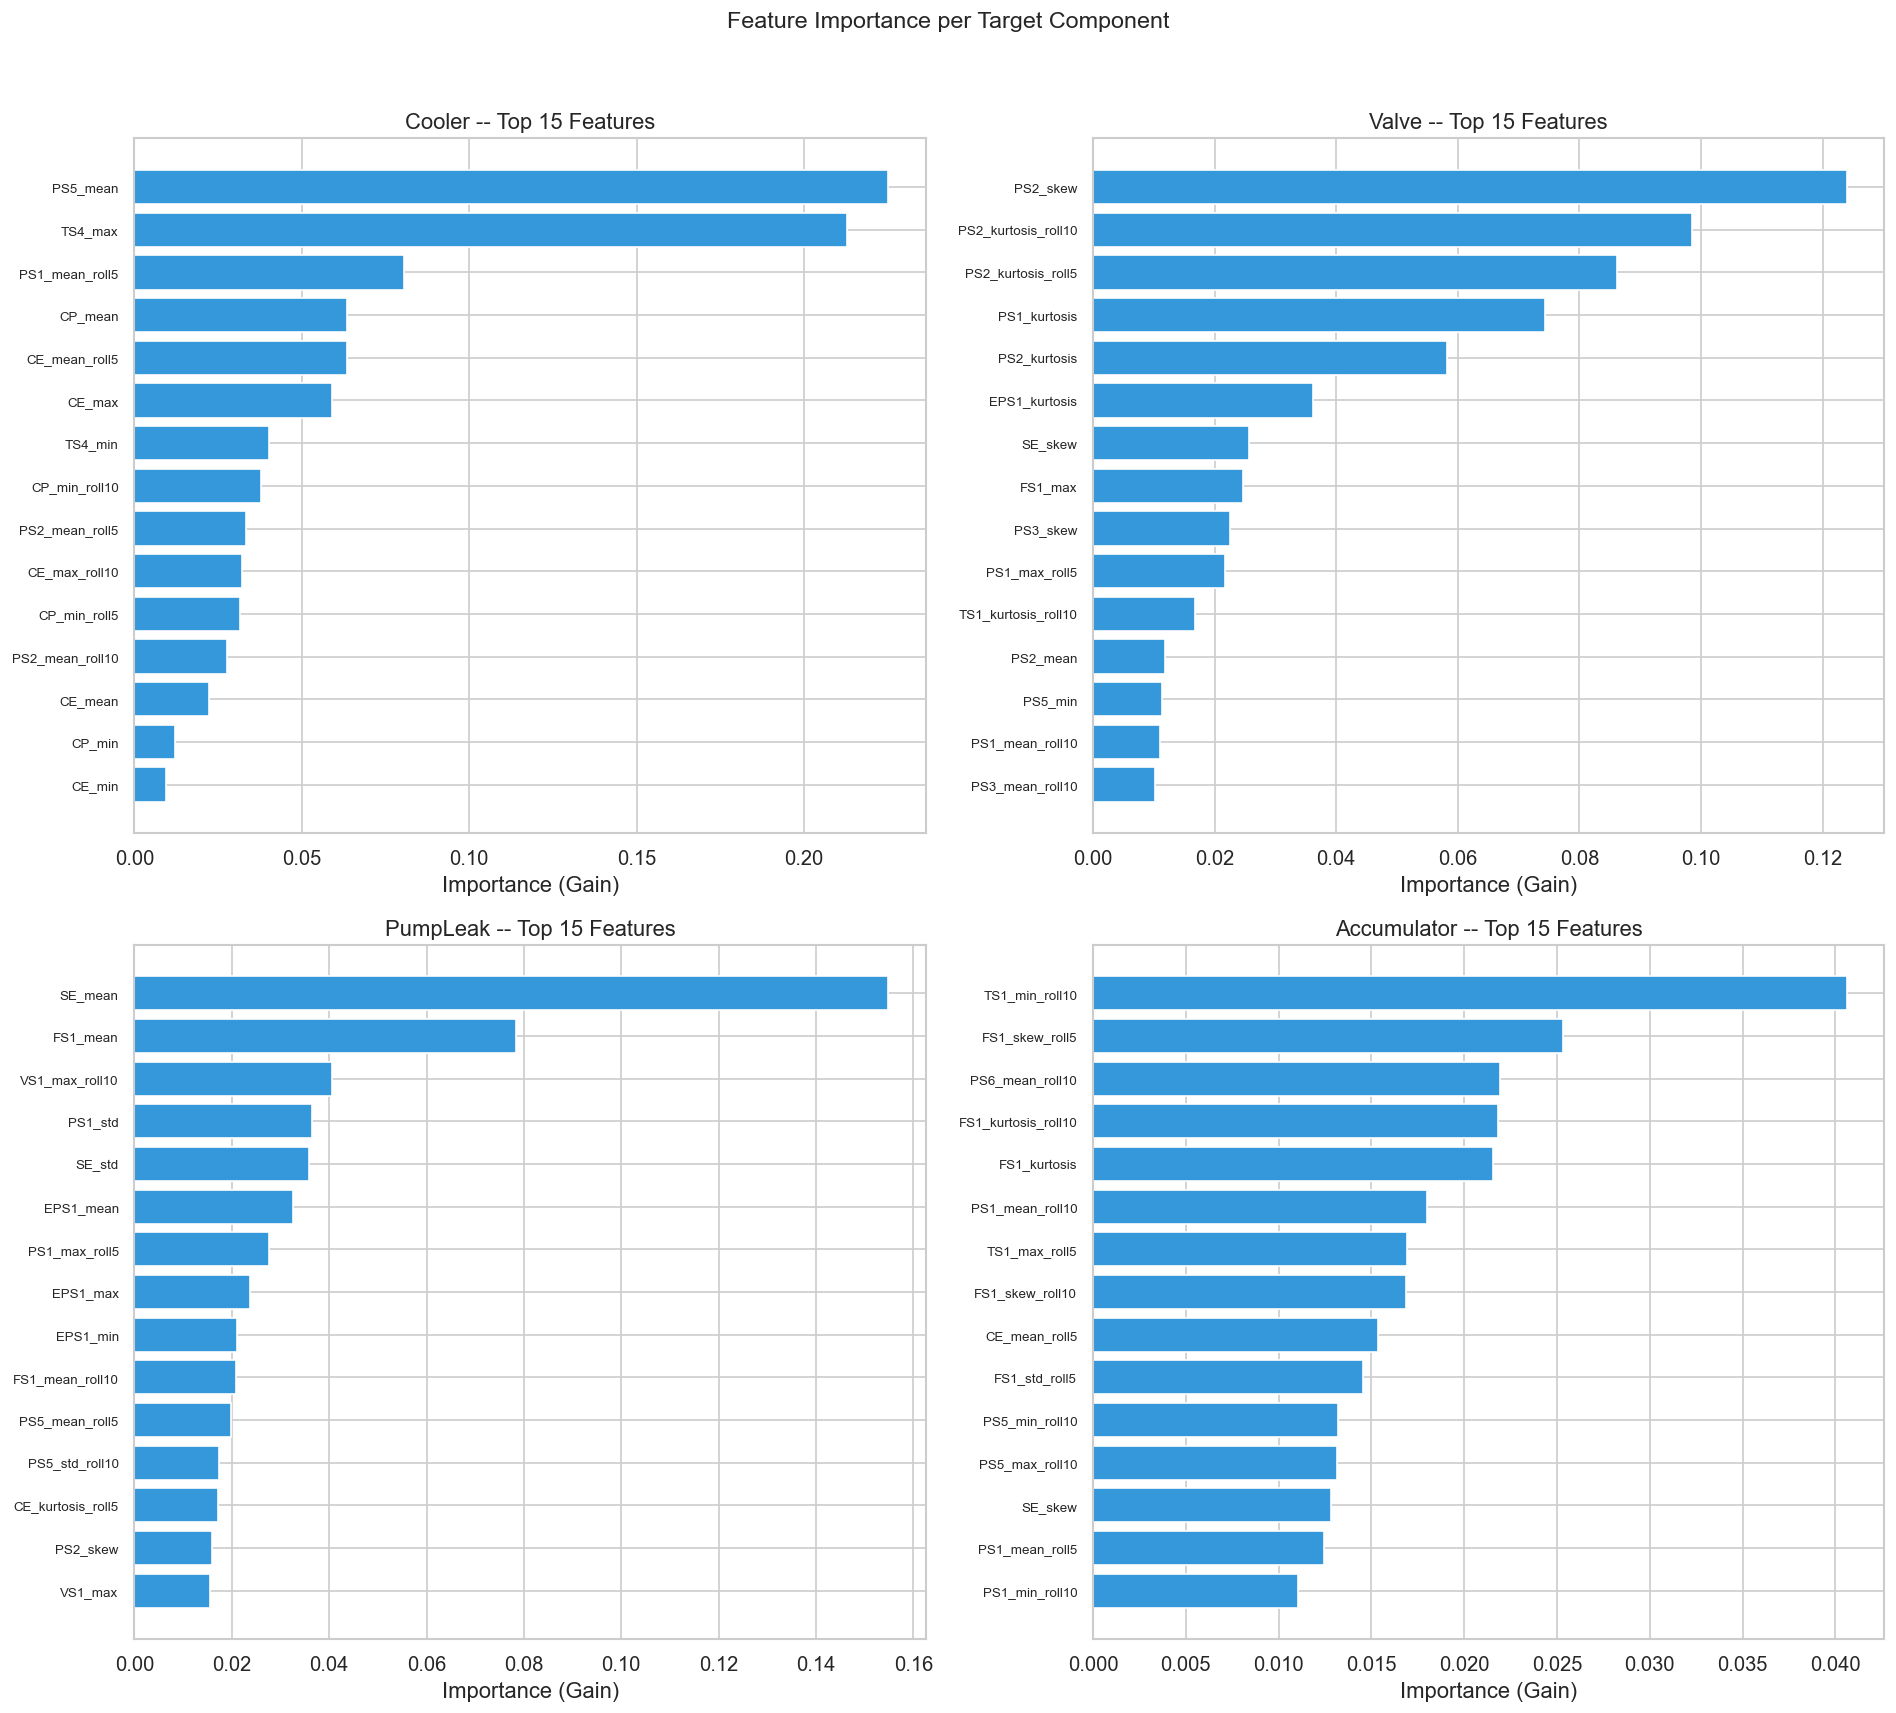

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for ax, name in zip(axes.flat, target_names):
    model = models[name]["model"]
    importances = model.feature_importances_
    top_k = 15
    top_idx = np.argsort(importances)[-top_k:]
    top_features = np.array(X_df.columns)[top_idx]
    top_importances = importances[top_idx]

    ax.barh(range(top_k), top_importances, color="#3498db")
    ax.set_yticks(range(top_k))
    ax.set_yticklabels(top_features, fontsize=8)
    ax.set_xlabel("Importance (Gain)")
    ax.set_title(f"{name} -- Top {top_k} Features")

plt.suptitle("Feature Importance per Target Component", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("models/a2_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

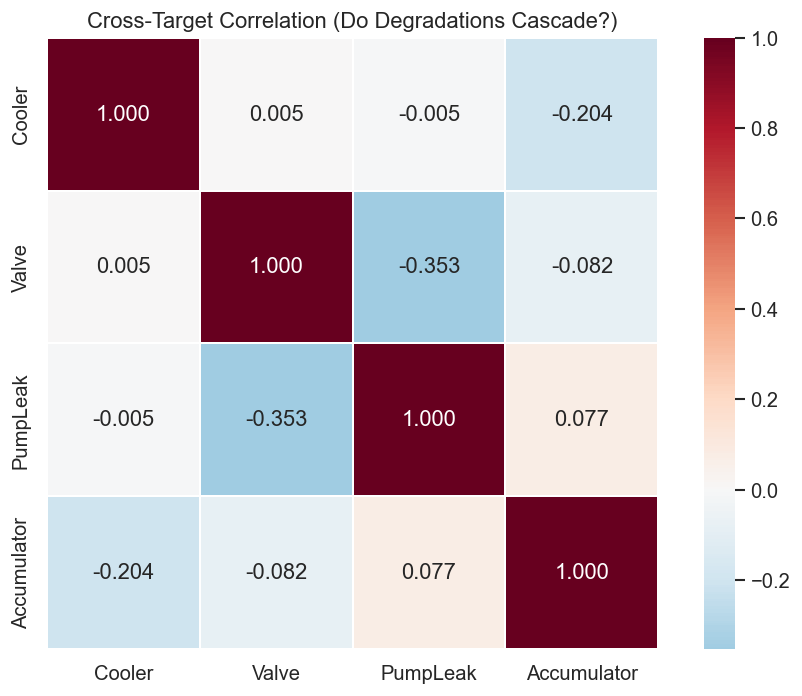

In [12]:
# Cross-target correlation analysis
# Do component degradations tend to co-occur?
target_df = pd.DataFrame(targets)
corr = target_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            square=True, ax=ax, linewidths=1)
ax.set_title("Cross-Target Correlation (Do Degradations Cascade?)")
plt.tight_layout()
plt.savefig("models/a2_target_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. SHAP Interpretability -- Cooler Condition

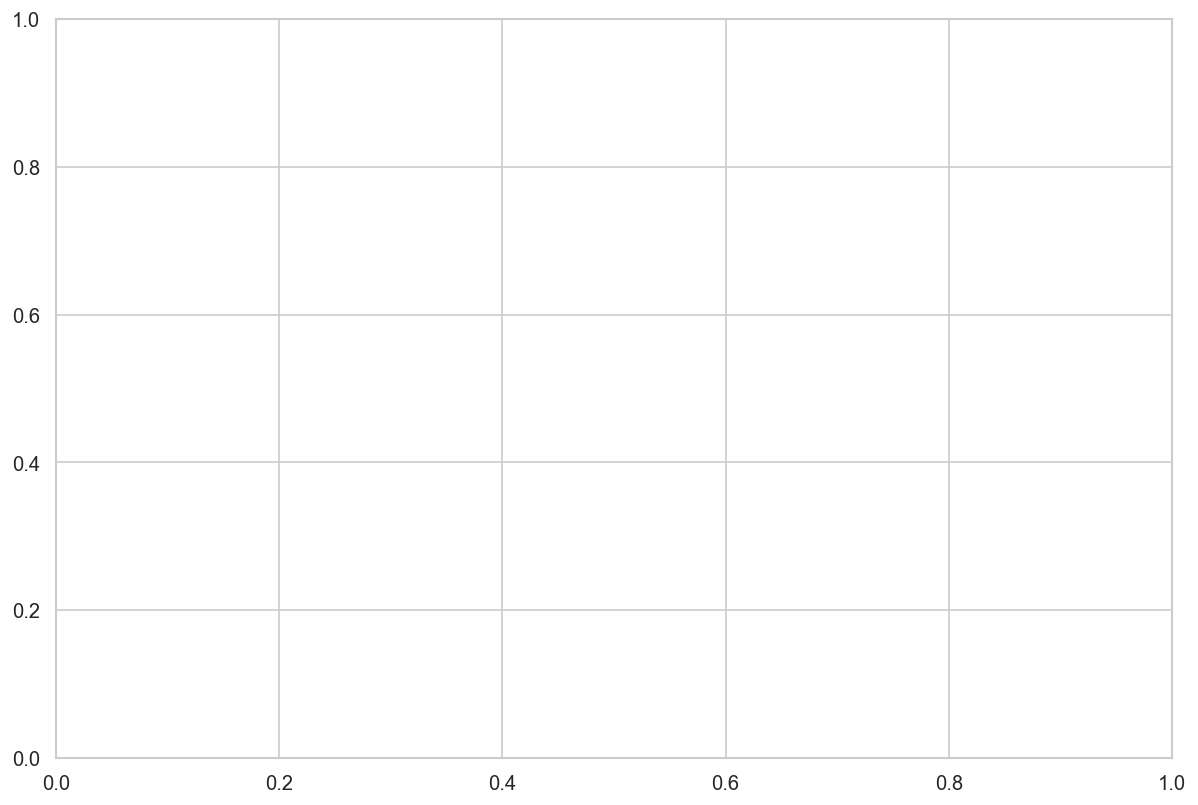

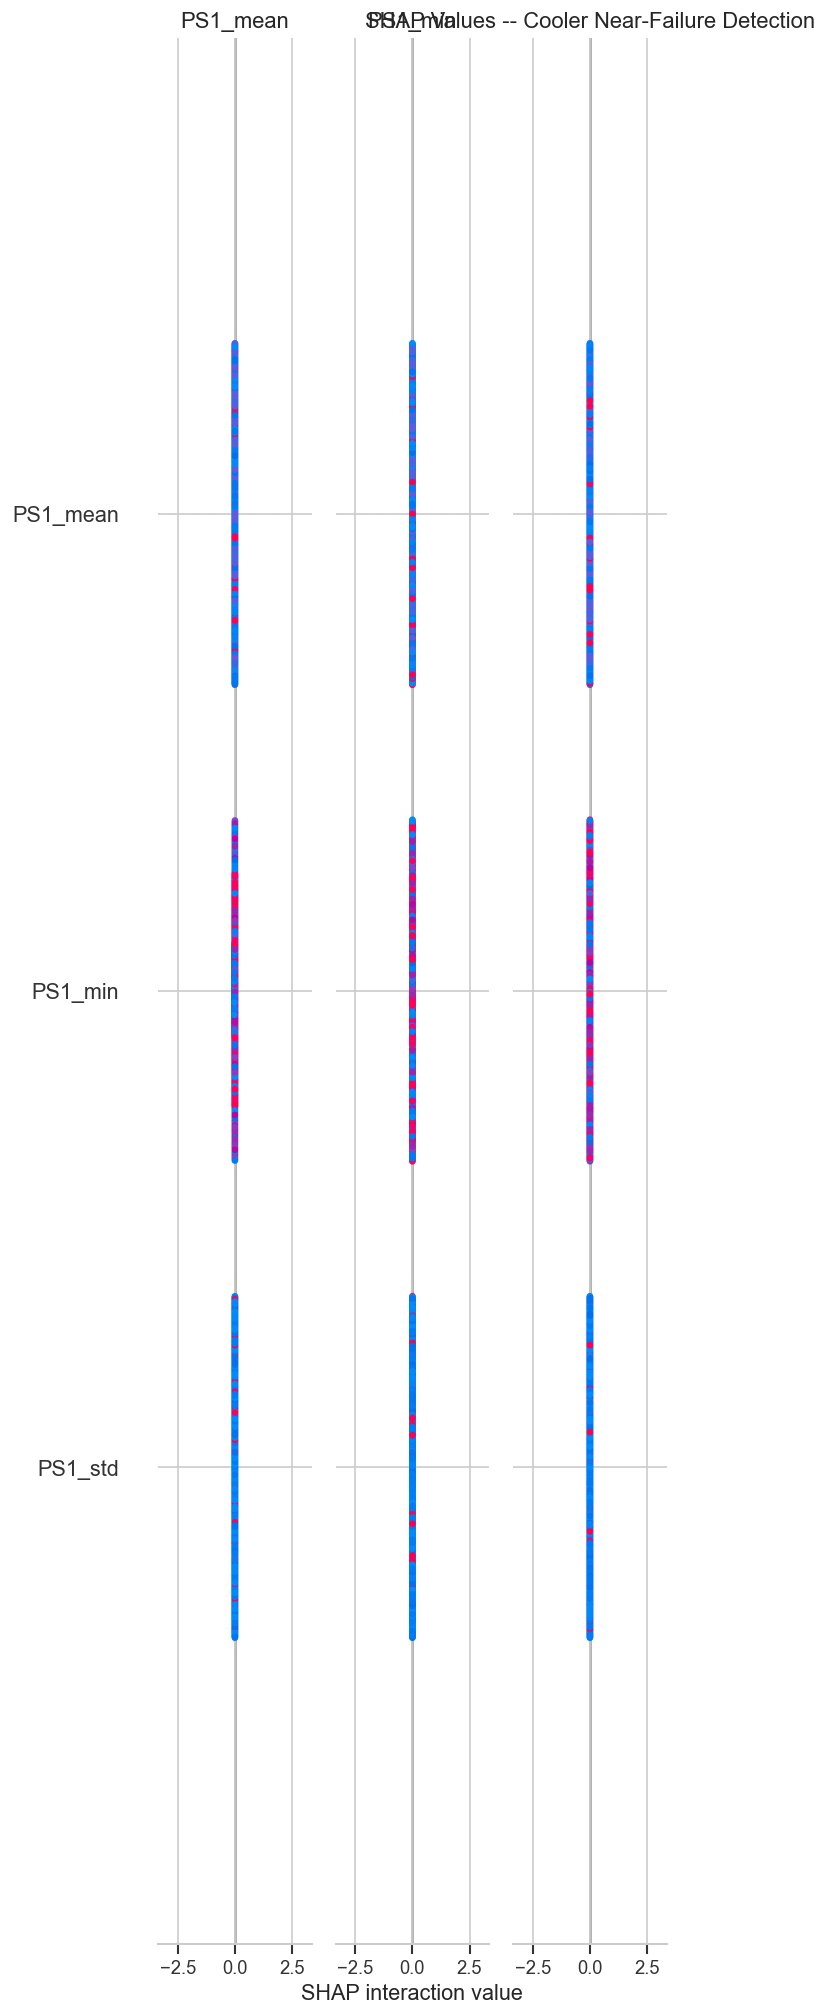

In [13]:
import shap

# SHAP for the Cooler model (most interpretable 3-class problem)
cooler_model = models["Cooler"]["model"]
explainer = shap.TreeExplainer(cooler_model)
shap_values = explainer.shap_values(X_test_scaled)

# For multi-class, shap_values is a list of arrays (one per class)
# Show the summary for the "near failure" class (class 0 = 3%)
fig, ax = plt.subplots(figsize=(12, 8))
if isinstance(shap_values, list):
    # Show summary for the worst condition class
    shap.summary_plot(shap_values[0], X_test_scaled,
                      feature_names=list(X_df.columns), show=False, max_display=20)
else:
    shap.summary_plot(shap_values, X_test_scaled,
                      feature_names=list(X_df.columns), show=False, max_display=20)
plt.title("SHAP Values -- Cooler Near-Failure Detection")
plt.tight_layout()
plt.savefig("models/a2_shap_cooler.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Model Export

In [14]:
# Save all 4 models with their encoders and the shared scaler
for name in target_names:
    payload = {
        "model": models[name]["model"],
        "label_encoder": models[name]["encoder"],
        "best_params": results[name]["best_params"],
    }
    filename = f"a2_{name.lower()}_classifier.joblib"
    joblib.dump(payload, MODEL_DIR / filename)

# Save shared artifacts
joblib.dump({
    "scaler": scaler,
    "feature_columns": list(X_df.columns),
    "target_names": target_names,
    "sensor_names": list(SENSORS.keys()),
}, MODEL_DIR / "a2_shared_config.joblib")

print(f"Models saved to {MODEL_DIR.resolve()}")
for f in sorted(MODEL_DIR.glob("a2_*.joblib")):
    print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")

Models saved to C:\Users\MSI\Documents\jesa\notebooks\models
  a2_accumulator_classifier.joblib (1364.2 KB)
  a2_cooler_classifier.joblib (468.5 KB)
  a2_pumpleak_classifier.joblib (582.0 KB)
  a2_shared_config.joblib (14.9 KB)
  a2_valve_classifier.joblib (1009.5 KB)


## 11. Verification Summary

In [15]:
print("=" * 60)
print("A2 CONDITION ESTIMATION -- VERIFICATION SUMMARY")
print("=" * 60)
print()

all_pass = True
for name in target_names:
    acc = results[name]["accuracy"]
    f1m = results[name]["f1_macro"]
    acc_pass = "PASS" if acc >= 0.90 else "BELOW TARGET"
    f1_pass = "PASS" if f1m >= 0.85 else "BELOW TARGET"
    if acc < 0.90 or f1m < 0.85:
        all_pass = False
    print(f"{name:15s}:  Accuracy={acc:.4f} [{acc_pass}]  Macro-F1={f1m:.4f} [{f1_pass}]")

print()
model_files = list(MODEL_DIR.glob("a2_*.joblib"))
print(f"Model artifacts: {len(model_files)} files saved")
for f in sorted(model_files):
    print(f"  {f.name}")
print()
print(f"Overall: {'ALL TARGETS PASS' if all_pass else 'SOME TARGETS BELOW THRESHOLD -- review above'}")
print("Notebook execution: COMPLETE")

A2 CONDITION ESTIMATION -- VERIFICATION SUMMARY

Cooler         :  Accuracy=1.0000 [PASS]  Macro-F1=1.0000 [PASS]
Valve          :  Accuracy=0.9887 [PASS]  Macro-F1=0.9867 [PASS]
PumpLeak       :  Accuracy=0.9955 [PASS]  Macro-F1=0.9955 [PASS]
Accumulator    :  Accuracy=1.0000 [PASS]  Macro-F1=1.0000 [PASS]

Model artifacts: 5 files saved
  a2_accumulator_classifier.joblib
  a2_cooler_classifier.joblib
  a2_pumpleak_classifier.joblib
  a2_shared_config.joblib
  a2_valve_classifier.joblib

Overall: ALL TARGETS PASS
Notebook execution: COMPLETE
